In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"

import healpy as hp
import pollux
import pyccl
import scipy.stats
from tqdm.auto import trange

import pickle
import sacc

import scipy


In [3]:
sim_root = '/pscratch/sd/d/desc/HOS_Sims/'
save_dir_root = os.path.join(os.environ["PSCRATCH"], "HOS_Sims_gaussian")
sim_relative_path = 'HACC150_3'

nside = 8192
seed = 0
tomo = 'SRDv1_nz'

kk = np.geomspace(1e-5, 1e3, 400)
lk = np.log(kk)
aa = np.linspace(0, 1, 5)  # splines need at least few points!

snaps = [4, 3, 2, 1]


# Snapshot sampling

In [4]:
Nz = 100

def get_dndz(zz):
    aa = 1. / (1. + zz)
    dVdz = pyccl.comoving_angular_distance(reader.cosmo, aa)**2 / pyccl.background.h_over_h0(reader.cosmo, aa)
    return dVdz / np.trapz(dVdz, zz)  # rough normalization


def compute_weights(tracer, zmin, zmax):
    chi_min, chi_max = pyccl.comoving_radial_distance(reader.cosmo, 1 / (1 + zmin)), pyccl.comoving_radial_distance(reader.cosmo, 1 / (1 + zmax))
    return scipy.integrate.quad(lambda chi: tracer.get_kernel(chi), chi_min, chi_max)[0]


*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x886b0df985b7529f
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 4 snapshots, returns 26 snapshots
*** Map builder (shell_hacc_seed12345) ***
  - Number of maps = 26
  - Maps saved to /pscratch/sd/j/jmena/HOS_Sims_gaussian/HACC150_3/gsims_nside8192/snap_e

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

Loading workspace in /pscratch/sd/j/jmena/HOS_Sims_gaussian/wsp_nside8192.wsp


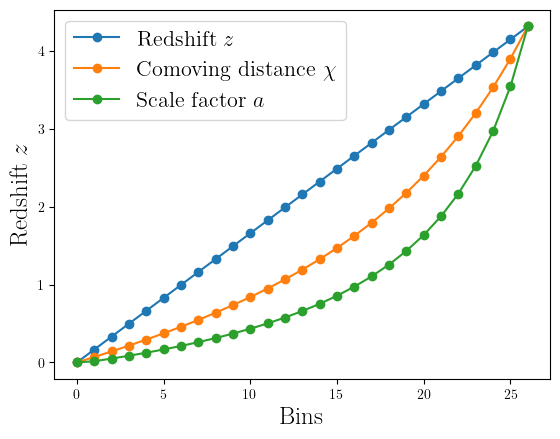

z
chi
a
*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x886b0df985b7529f
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 3 snapshots, returns 34 snapshots
*** Map builder (shell_hacc_seed12345) ***
  - Number of maps = 34
  - Maps saved to /pscratch/sd/j/jmena/HOS_Sims_gaussian/HACC150_3/gsims_nside819

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

Loading workspace in /pscratch/sd/j/jmena/HOS_Sims_gaussian/wsp_nside8192.wsp


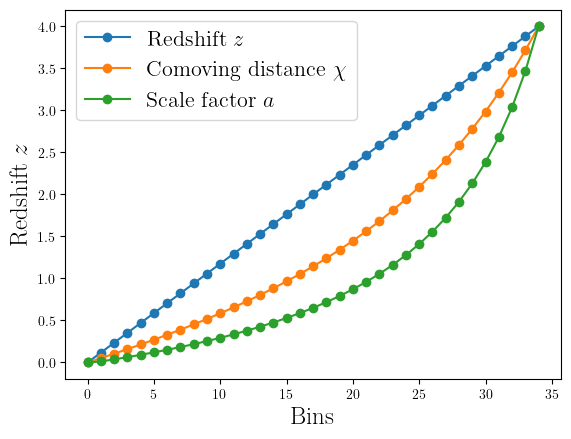

z
chi
a
*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x886b0df985b7529f
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 2 snapshots, returns 51 snapshots
*** Map builder (shell_hacc_seed12345) ***
  - Number of maps = 51
  - Maps saved to /pscratch/sd/j/jmena/HOS_Sims_gaussian/HACC150_3/gsims_nside819

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

Loading workspace in /pscratch/sd/j/jmena/HOS_Sims_gaussian/wsp_nside8192.wsp


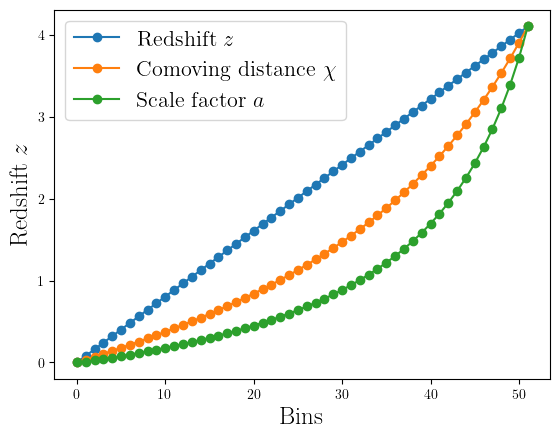

z
chi
a
*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x886b0df985b7529f
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
*** Map builder (shell_hacc_seed12345) ***
  - Number of maps = 101
  - Maps saved to /pscratch/sd/j/jmena/HOS_Sims_gaussian/HACC150_3/gsims_nside8192/snap_every1/seed0/
  - Box size = 845.07 Mpc
*** Map builder (k

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

Loading workspace in /pscratch/sd/j/jmena/HOS_Sims_gaussian/wsp_nside8192.wsp


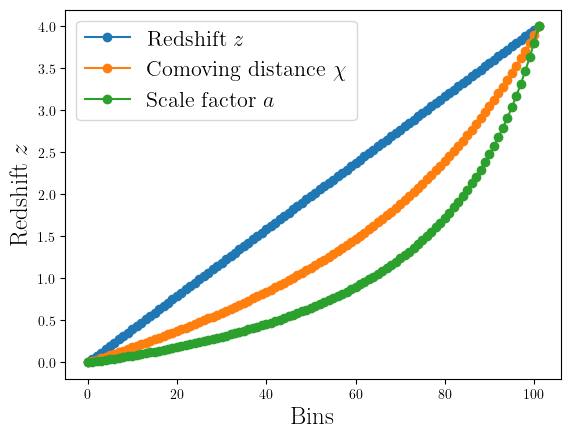

z
chi
a


In [5]:
cls_density = {}
cls_kappa = {}

for snap in snaps:
    # Initialize objects
    runname = f'gsims_nside{nside}/snap_every{snap}/seed{seed}/'
    
    reader = pollux.HACCReader(path=os.path.join(sim_root, sim_relative_path), run_params='run/indat.params', snap_sub_every_n=snap)
    builder = pollux.SnapshotShellBuilder(
        reader, nside, save_dir=os.path.join(save_dir_root, sim_relative_path, runname), dtype=np.float32, save_density=True, wsp_dir=save_dir_root)#, nlb=40)
    dndz = np.loadtxt('data/SRDv1_nz.txt')
    nzs = [(dndz[:, 0], dndz[:, i]) for i in range(1, 6)]
    lensing = pollux.BornLensingBuilder(builder, nzs, kappa_dir='SRDv1_nz', wsp_dir=save_dir_root, sigma_e=0.3)#, nlb=40)

    # Limber prediction
    ell, cls_th_full, cls_th_err = lensing.predict_cls(error_bars=True)

    wsp = builder.get_cls_wsp()
    bpws = wsp.get_bandpower_windows()[0, :, 0, :]

    # Linear in scale factor
    z_edges_a = builder.shell_edges_redshift()
    zmin, zmax = z_edges_a[0], z_edges_a[-1]
    
    # Linear in comoving distance
    chi_edges = np.linspace(
        pyccl.comoving_radial_distance(reader.cosmo, 1 / (1 + zmin)), pyccl.comoving_radial_distance(reader.cosmo, 1 / (1 + zmax)), builder.nshells + 1)
    z_edges_chi = (1 / pyccl.scale_factor_of_chi(reader.cosmo, chi_edges) - 1.)
    
    # Linear in redshift
    z_edges_z = np.linspace(zmin, zmax, builder.nshells + 1)
    
    z_edges_binnings = [z_edges_z, z_edges_chi, z_edges_a]
    labels_binnings = ["z", "chi", "a"]
    labels_binnings_plots = ['Redshift $z$', r'Comoving distance $\chi$', 'Scale factor $a$']
    
    for z, l in zip(z_edges_binnings, labels_binnings_plots):
        plt.plot(z, 'o-', label=l)
    plt.legend(fontsize=16)
    plt.xlabel('Bins', fontsize=18)
    plt.ylabel('Redshift $z$', fontsize=18)
    plt.show()

    # Binned predictions
    cls_density[snap] = {}
    cls_kappa[snap] = {}
    
    for z_edges, l in zip(z_edges_binnings, labels_binnings):
        print(l)
    
        # Tracers
        density_tracers = []
        for ishell in range(builder.nshells):
            zz = np.linspace(z_edges[ishell], z_edges[ishell + 1], Nz)
            dndz = get_dndz(zz)
            density_tracers.append(pyccl.NumberCountsTracer(reader.cosmo, has_rsd=False, dndz=(zz, dndz), bias=(zz, np.ones_like(zz))))
    
        cls_density[snap][l] = {}
        # Full
        for ishell, t in enumerate(density_tracers):
            cls_density[snap][l][ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(reader.cosmo, t, t, np.arange(3 * nside)))
    
        cls_kappa[snap][l] = {}
        kappa_tracers = lensing.get_tracers()
        for i in range(lensing.nmaps):
            for j in range(lensing.nmaps):
                cls_kappa[snap][l][i, j] = np.sum([
                    compute_weights(kappa_tracers[i], z_edges[ishell], z_edges[ishell + 1]) *
                    compute_weights(kappa_tracers[j], z_edges[ishell], z_edges[ishell + 1]) * cls_density[snap][l][ishell, ishell] for ishell in range(builder.nmaps)
                ], axis=0)
                

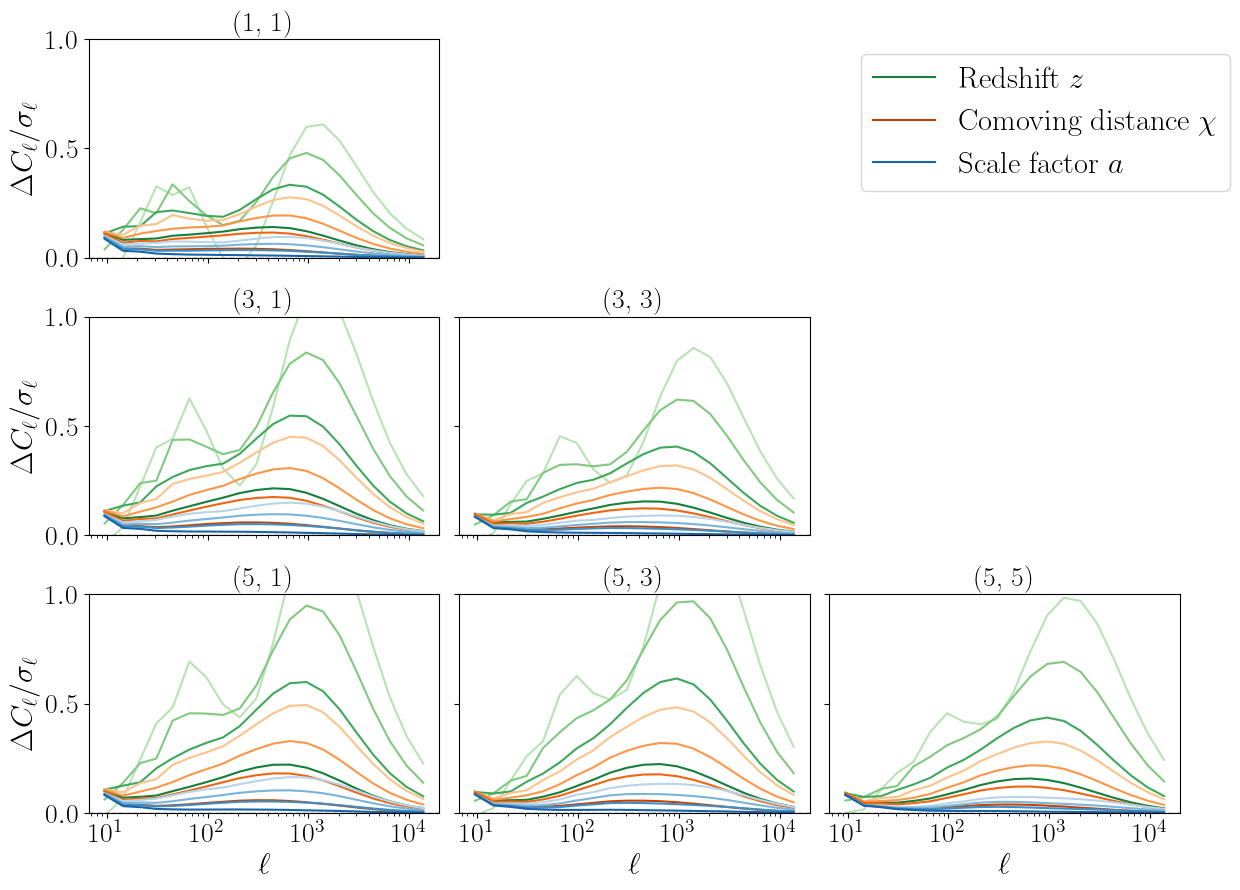

In [6]:
import matplotlib as mpl

zbins = np.arange(5)
zbins = [0, 2, 4]
nz = len(zbins)

fig, axes = plt.subplots(nz, nz, figsize=(4 * nz, 3 * nz), sharey="row")

colors = {l: cmap(np.linspace(0.3, 0.8, len(snaps))) for l,cmap in zip(labels_binnings, [mpl.cm.Greens, mpl.cm.Oranges, mpl.cm.Blues])}

for i, map1 in enumerate(zbins):
    for j, map2 in enumerate(zbins):
        ax = axes[i, j]
        if i >= j:

            
            for z, l, label in zip(z_edges_binnings, labels_binnings, labels_binnings_plots):
                for c,snap in enumerate(snaps):
                    ax.plot(ell, (cls_kappa[snap][l][i, j] - cls_th_full[i, j]) / cls_th_err[i, j], label=label if c==len(snaps)-1 else None, c=colors[l][c])
                
            ax.set_xscale("log")
            
            if map1 == zbins[-1]:
                ax.set_xlabel(r'$\ell$', fontsize=22)
            else:
                ax.set_xticklabels([])

            if map2 == 0:
                ax.set_ylabel(r'$\Delta C_\ell/\sigma_\ell$', fontsize=22)

            ax.set_ylim(0, 1)

            ax.axhline(y=0., lw=1, c='.2', ls='--')

            ax.tick_params(axis='x', labelsize=20)
            ax.tick_params(axis='y', labelsize=20)
            ax.set_title(f'({map1+1}, {map2+1})', fontsize=20)

        else:
            ax.axis('off')

plt.tight_layout()
plt.subplot(nz, nz, 1)
plt.legend(bbox_to_anchor=(nz + 0.3, 1), loc='upper right', fontsize=22)

plt.savefig(f"plots/binning_1.pdf", bbox_inches="tight")


# Lightcone discretization and in-shell evolution

In [7]:
cls_th_cst = {}
cls_th_evo = {}

for snap in snaps:
    cls_th_cst[snap] = {}
    cls_th_evo[snap] = {}

    runname = f'gsims_nside{nside}/snap_every{snap}/seed{seed}/'

    reader = pollux.HACCReader(path=os.path.join(sim_root, sim_relative_path), run_params='run/indat.params', snap_sub_every_n=snap)
    builder = pollux.SnapshotShellBuilder(
        reader, nside, save_dir=os.path.join(save_dir_root, sim_relative_path, runname), dtype=np.float32, save_density=True, wsp_dir=save_dir_root)
    dndz = np.loadtxt('data/SRDv1_nz.txt')
    nzs = [(dndz[:, 0], dndz[:, i]) for i in range(1, 6)]
    lensing = pollux.BornLensingBuilder(builder, nzs, kappa_dir='SRDv1_nz', wsp_dir=save_dir_root)

    wsp = builder.get_cls_wsp()
    bpws = wsp.get_bandpower_windows()[0, :, 0, :]

    # Evolution within shells
    zshells = reader.zsnapshots
    cls_density_evo = {}
    for ishell, t in enumerate(builder.get_tracers()):
        cls_density_evo[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(reader.cosmo, t, t, np.arange(3 * nside)))

    # Cst within shells
    zshells = reader.zsnapshots
    cls_density_cst = {}
    for ishell, t in enumerate(builder.get_tracers()):
        # Create constant P(k,z) at P(k,zsnapshot)
        pk = reader.cosmo.nonlin_matter_power(kk, 1.0 / (1.0 + zshells[ishell]))
        pk_cst = pyccl.pk2d.Pk2D(a_arr=aa, lk_arr=lk, pk_arr=np.array([np.log(pk)] * len(aa)), is_logp=True)
        cls_density_cst[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(reader.cosmo, t, t, np.arange(3 * nside), p_of_k_a=pk_cst))

    for i in range(lensing.nmaps):
        for j in range(lensing.nmaps):
            cls_th_evo[snap][i, j] = np.sum(
                [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * cls_density_evo[ishell, ishell] for ishell in range(builder.nmaps)],
                axis=0)
            cls_th_cst[snap][i, j] = np.sum(
                [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * cls_density_cst[ishell, ishell] for ishell in range(builder.nmaps)],
                axis=0)
            

*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x886b0df985b7529f
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 4 snapshots, returns 26 snapshots
*** Map builder (shell_hacc_seed12345) ***
  - Number of maps = 26
  - Maps saved to /pscratch/sd/j/jmena/HOS_Sims_gaussian/HACC150_3/gsims_nside8192/snap_e

In [8]:
ell, cls_th_full, cls_th_err = lensing.predict_cls(error_bars=True)

Loading workspace in /pscratch/sd/j/jmena/HOS_Sims_gaussian/wsp_nside8192.wsp


[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

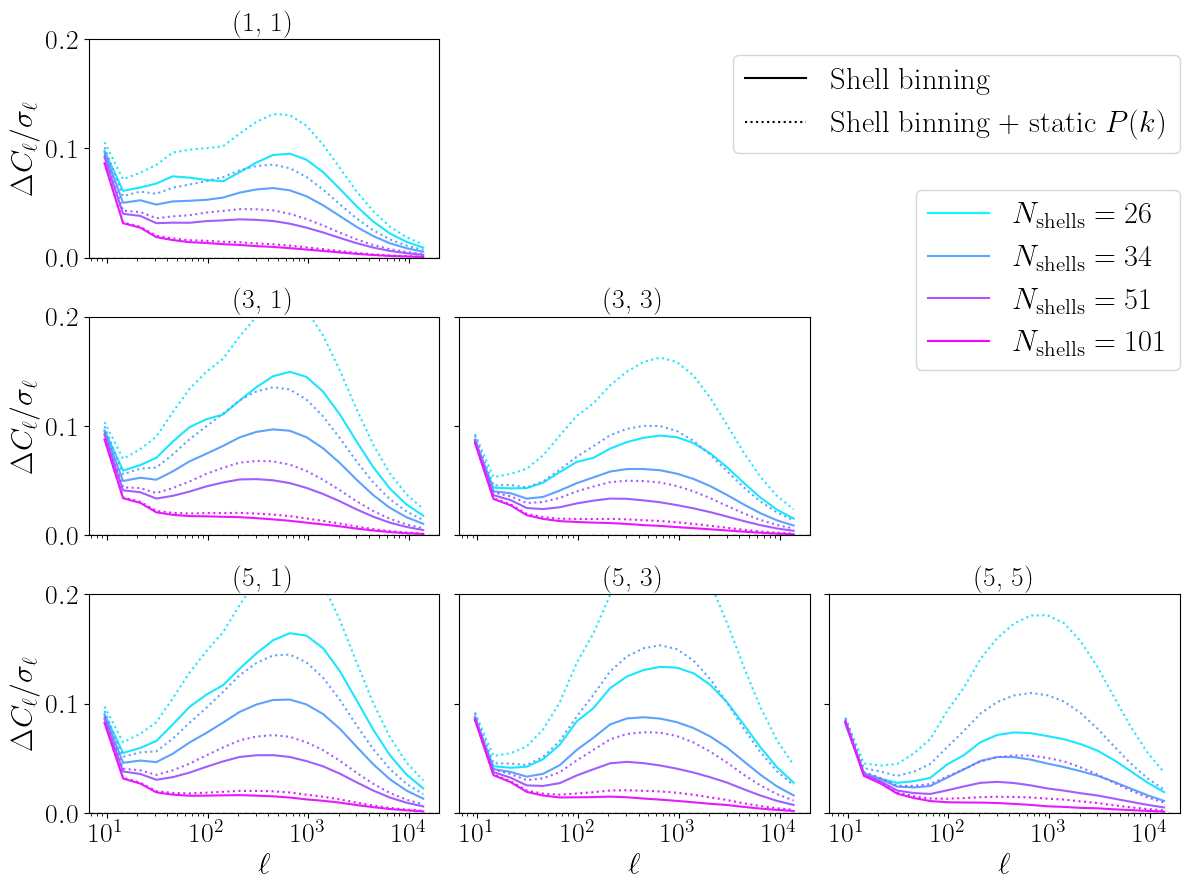

In [9]:
zbins = np.arange(5)
zbins = [0, 2, 4]
nz = len(zbins)

nshells = {4: 26, 3: 34, 2: 51, 1: 101}

fig, axes = plt.subplots(nz, nz, figsize=(4 * nz, 3 * nz), sharey="row")

colormap = plt.cm.cool
norm = plt.Normalize(0, len(nshells) - 1)
values = np.linspace(norm.vmin, norm.vmax, len(nshells))
normalized_values = norm(values)

scaled_values = 0.1 + normalized_values * 0.8
colors = colormap(scaled_values)

tomos = ['SRDv1_nz', 'stack_density']

legend1_handles = []
legend2_handles = []

dummy_ax = fig.add_subplot(111, frameon=False)
dummy_ax.axis('off')

for i, map1 in enumerate(zbins):
    for j, map2 in enumerate(zbins):
        ax = axes[i, j]
        if i >= j:

            for k, tomo in enumerate(tomos):
                for c, snap in enumerate(snaps):

                    if k == 1:
                        ax.plot(
                            ell, (cls_th_evo[snap][i, j] - cls_th_full[i, j]) / cls_th_err[i, j],
                            c=colors[c],
                            ls='-', label=fr"$N_{{\rm shells}}={nshells[snap]}$")
                        ax.plot(
                            ell, (cls_th_cst[snap][i, j] - cls_th_full[i, j]) / cls_th_err[i, j],
                            c=colors[c],
                            ls=':')

            ax.set_xscale("log")

            if map1 == 4:
                ax.set_xlabel(r'$\ell$', fontsize=22)
            else:
                ax.set_xticklabels([])

            if map2 == 0:
                ax.set_ylabel(r'$\Delta C_\ell/\sigma_\ell$', fontsize=22)

            ax.set_ylim(0, 0.2)

            ax.axhline(y=0., lw=1, c='.2', ls='--')

            ax.tick_params(axis='x', labelsize=20)
            ax.tick_params(axis='y', labelsize=20)
            ax.set_title(f'({map1+1}, {map2+1})', fontsize=20)

        else:
            ax.axis('off')

line1, = dummy_ax.plot([], [], c='black', ls='-', label='Shell binning')
line2, = dummy_ax.plot([], [], c='black', ls=':', label='Shell binning + static $P(k)$')
legend1_handles.extend([line1, line2])

for c, snap in enumerate(snaps):
    line, = dummy_ax.plot([], [], c=colormap(norm(c)), ls='-', label=fr"$N_{{\rm shells}}={nshells[snap]}$")
    legend2_handles.append(line)

fig.legend(handles=legend1_handles, bbox_to_anchor=(1, 0.95), loc='upper right', fontsize=22)
fig.legend(handles=legend2_handles, bbox_to_anchor=(1, 0.8), loc='upper right', fontsize=22)

plt.tight_layout()

plt.savefig(f"plots/binning_2.pdf", bbox_inches="tight")
